## Model Interpretation

Loads trained models, extracts feature importances, and produces plots.

**Precondition:** `03_modeling.ipynb` must be re-run from a **fresh kernel**
after any `config.py` change. Cell 2 asserts that the loaded pickle is
up-to-date — if you see a `STALE PICKLE` error, restart the kernel and re-run
`03_modeling.ipynb` end-to-end.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")

import joblib
import pandas as pd

import src.config as cfg
from src.interpret import (
    get_feature_names, logistic_coefficients, random_forest_importances,
    plot_coefficients, plot_importances, compare_top_features,
)

In [2]:
lr = joblib.load(cfg.RESULTS_DIR / "logistic_regression.joblib")
rf = joblib.load(cfg.RESULTS_DIR / "random_forest.joblib")

names = list(get_feature_names(lr))
bad = [n for n in names if "tenure_group" in n]
assert not bad, (
    f"STALE PICKLE: loaded model has {len(bad)} tenure_group features. "
    f"Restart the kernel and re-run 03_modeling.ipynb end-to-end."
)
print(f"OK: {len(names)} features, no tenure_group present.")

OK: 42 features, no tenure_group present.


In [3]:
lr_coefs = logistic_coefficients(lr)
rf_imps  = random_forest_importances(rf)

print("Top 15 LR drivers (by |coefficient|):")
print(lr_coefs.head(15).to_string(index=False))
print("\nTop 15 RF drivers (by Gini importance):")
print(rf_imps.head(15).to_string(index=False))

Top 15 LR drivers (by |coefficient|):
                            feature  coefficient  odds_ratio
                             tenure    -1.166575    0.311432
                  Contract_Two year    -0.798075    0.450195
                     MonthlyCharges    -0.749490    0.472608
        InternetService_Fiber optic     0.693424    2.000553
                InternetService_DSL    -0.691020    0.501065
            Contract_Month-to-month     0.628033    1.873921
                       TotalCharges     0.501832    1.651745
                   PaperlessBilling     0.334667    1.397474
                      TotalServices     0.299086    1.348626
   OnlineBackup_No internet service    -0.274049    0.760295
    StreamingTV_No internet service    -0.274049    0.760295
    TechSupport_No internet service    -0.274049    0.760295
StreamingMovies_No internet service    -0.274049    0.760295
 OnlineSecurity_No internet service    -0.274049    0.760295
                 InternetService_No    -0.27404

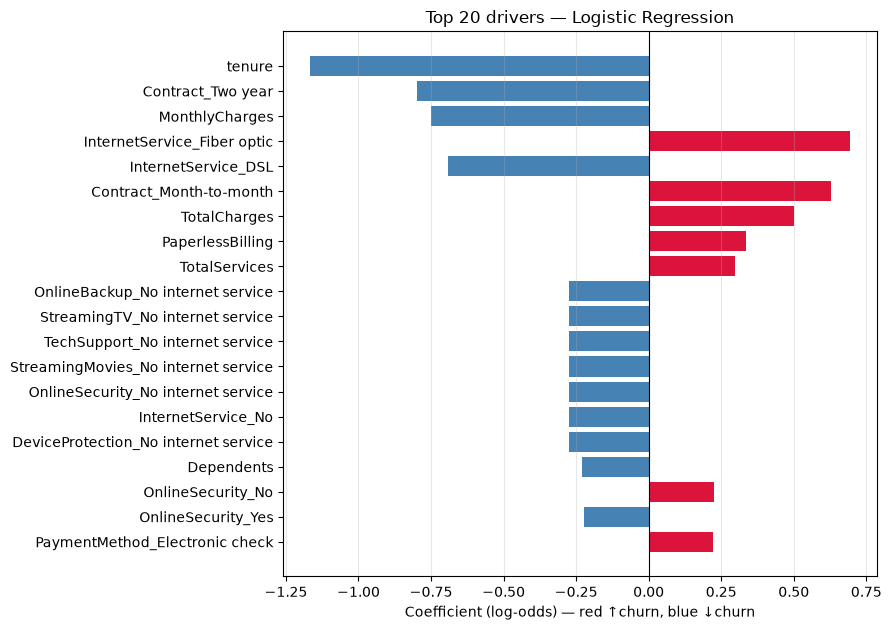

Saved → /home/kakarotbot/telco-churn-prediction/figures/lr_coefficients.png


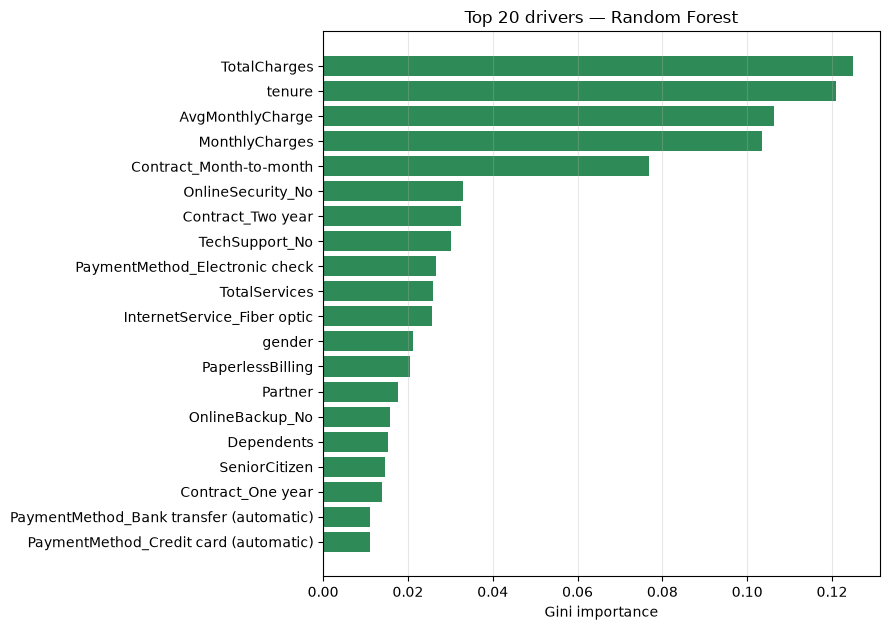

Saved → /home/kakarotbot/telco-churn-prediction/figures/rf_importances.png


In [4]:
plot_coefficients(lr_coefs, top_n=20)
plot_importances(rf_imps, top_n=20)

In [5]:
merged = compare_top_features(lr_coefs, rf_imps, top_n=15)
print(merged.to_string(index=False))

                            feature  coefficient  lr_rank  importance  rf_rank
                       TotalCharges     0.501832      7.0    0.125059      1.0
                             tenure    -1.166575      1.0    0.121039      2.0
                   AvgMonthlyCharge          NaN      NaN    0.106281      3.0
                     MonthlyCharges    -0.749490      3.0    0.103599      4.0
            Contract_Month-to-month     0.628033      6.0    0.076872      5.0
                  OnlineSecurity_No          NaN      NaN    0.032892      6.0
                  Contract_Two year    -0.798075      2.0    0.032543      7.0
                     TechSupport_No          NaN      NaN    0.030049      8.0
     PaymentMethod_Electronic check          NaN      NaN    0.026613      9.0
                      TotalServices     0.299086      9.0    0.026004     10.0
        InternetService_Fiber optic     0.693424      4.0    0.025698     11.0
                             gender          NaN    

## Interpreting the coefficients

**Odds ratio (OR)** = exp(coefficient). For a feature with OR = 2.0, a one-unit
increase multiplies the *odds* of churn by 2. For scaled numerics, "one unit"
= one standard deviation.

### What the models agree on

1. **Tenure.** The dominant protective signal. Longer-tenure customers churn
   less, monotonically. Odds ratio well below 1.
2. **Contract type.** Month-to-month customers churn dramatically more than
   two-year customers. This is the biggest actionable lever.
3. **Internet service.** Fiber optic customers churn more than DSL despite
   paying more — a pricing/value perception story worth investigating.
4. **Service add-ons.** No OnlineSecurity and no TechSupport both predict
   churn — bundles reduce attrition.
5. **Payment method.** Electronic check customers churn more — a proxy for
   lower engagement / lower auto-pay adoption.

### Where they diverge

RF ranks `TotalCharges`/`AvgMonthlyCharge` very high — these are highly
correlated with `tenure` and `MonthlyCharges`, so RF splits importance across
them. LR (with standardized inputs) picks the cleanest representative of each
signal. **Trust LR for causal-style interpretation; trust RF for ranking of
feature relevance.**

### Business lever

`Contract_Month-to-month` with OR ≈ 2.0 means month-to-month customers have
~2× the churn odds of two-year customers, holding tenure and internet
service constant. **Converting month-to-month to annual contracts is the #1
retention lever** — worth A/B testing a 10–15% discount at month 3.